# XGBoost vs SAP RPT: predictions before and after context engineering

## tl;dr
This notebook compares **both prediction models** on the same 128 held-out invoices. “Before” uses 128 randomly chosen labeled rows; “after” uses 128 class-balanced rows. The balanced strategy was chosen using SAP RPT validation results. Saved SAP RPT predictions are compared with locally reproduced XGBoost predictions on the **same context row IDs for each target and seed**.


## Context & methods

- Frozen source: `data/semantic_ablation/source_snapshot.csv` (1,152 synthetic invoices). Rows 1–1,024 are eligible for final context/training; rows 1,025–1,152 are the untouched holdout, with eight fraud cases.
- SAP RPT final predictions: `data/context_benchmark/selection_holdout_results.csv` and `selection_holdout_predictions.csv`. Validation choice: `selection_validation_results.csv`.
- XGBoost is retrained here on each matching 128-row random or balanced context, using the benchmark's unchanged `select_context` and `xgb_predict` functions. Each model predicts the same holdout rows. Five seeds define the context samples.
- Class balancing changes the number of positive examples, especially for fraud. XGBoost also applies its existing fraud class weight. These choices are part of the measured intervention; this is a descriptive comparison, not a causal model ranking.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / 'data/semantic_ablation/source_snapshot.csv').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))
from context_engineering import select_context, assert_no_leakage
from run_context_benchmark import xgb_predict, metric_row

source = pd.read_csv(ROOT / 'data/semantic_ablation/source_snapshot.csv')
pool, query = source.iloc[:1024].copy(), source.iloc[1024:].copy()
validation = pd.read_csv(ROOT / 'data/context_benchmark/selection_validation_results.csv')
sap_results = pd.read_csv(ROOT / 'data/context_benchmark/selection_holdout_results.csv')
sap_predictions = pd.read_csv(ROOT / 'data/context_benchmark/selection_holdout_predictions.csv')
targets = {'paid_late': 'Late payment', 'is_fraud': 'Fraud'}
seeds = (11, 23, 37, 41, 53)
assert len(query) == 128 and query.is_fraud.sum() == 8
assert_no_leakage(pool, query)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 120})


## Results

### Choose the “after” context from validation
The validation winner is chosen before using the final holdout. Only the four global strategies with five validation seeds are eligible.


In [ ]:
eligible = validation[validation.strategy.isin(['random', 'stratified', 'balanced', 'diversity'])]
chosen = (eligible.groupby(['target', 'strategy']).f1.mean()
          .groupby(level=0).idxmax().map(lambda item: item[1]).to_dict())
assert chosen == {'is_fraud': 'balanced', 'paid_late': 'balanced'}
display(pd.DataFrame({'Target': [targets[target] for target in targets],
                      'Selected after strategy': [chosen[target] for target in targets]}))


,Target,Selected after strategy
0,Late payment,balanced
1,Fraud,balanced


### Reproduce XGBoost predictions on matched rows
For each target and seed, the same selected invoice IDs are used for XGBoost training and SAP RPT context. The XGBoost prediction code matches the saved benchmark procedure; no SAP API call is made.


In [ ]:
xgb_rows = []
xgb_predictions = []
for target in targets:
    for strategy in ('random', chosen[target]):
        for seed in seeds:
            context, _ = select_context(pool, target, query.iloc[:1], strategy, 128, seed)
            assert_no_leakage(context, query)
            predicted, _, _, _ = xgb_predict(context, query, target, seed)
            metrics = metric_row(query[target].to_numpy(), predicted)
            xgb_rows.append({'model': 'XGBoost', 'strategy': strategy,
                             'target': target, 'seed': seed,
                             'context_positives': int(context[target].sum()), **metrics})
            xgb_predictions.extend({'model': 'XGBoost', 'strategy': strategy,
                                    'target': target, 'seed': seed,
                                    'invoice_id': invoice_id, 'actual': int(actual),
                                    'predicted': int(prediction)}
                                   for invoice_id, actual, prediction in
                                   zip(query.invoice_id, query[target], predicted))
xgb_results = pd.DataFrame(xgb_rows)
xgb_predictions = pd.DataFrame(xgb_predictions)
assert len(xgb_results) == 20 and len(xgb_predictions) == 20 * len(query)
matched_counts = xgb_results.merge(
    sap_results[['target', 'strategy', 'seed', 'context_positives']],
    on=['target', 'strategy', 'seed'], suffixes=('_xgb', '_sap'))
assert len(matched_counts) == 20
assert matched_counts.context_positives_xgb.equals(matched_counts.context_positives_sap)


### Side by side prediction scores
F1, precision and recall are class-1 measures. False positives and true positives are counts per 128 held-out invoices. Values below are means across five context seeds.


In [ ]:
sap = sap_results[sap_results.strategy.isin(['random', 'balanced'])].copy()
assert len(sap) == 20 and set(sap.model) == {'SAP-RPT'}
combined = pd.concat([xgb_results, sap], ignore_index=True)
combined['Stage'] = combined.strategy.map({'random': 'Before: random',
                                            'balanced': 'After: balanced'})
combined['Target'] = combined.target.map(targets)
summary = (combined.groupby(['Target', 'Stage', 'model'], sort=False)
           [['f1', 'precision', 'recall', 'true_positives',
             'false_positives', 'context_positives']].mean().round(3))
display(summary.rename(columns={'f1': 'F1', 'precision': 'Precision',
                                'recall': 'Recall', 'true_positives': 'True positives / 128',
                                'false_positives': 'False positives / 128',
                                'context_positives': 'Positive context rows'}))


F1  ...  Positive context rows
Target       Stage           model           ...                       
Late payment Before: random  XGBoost  0.565  ...                   54.0
             After: balanced XGBoost  0.550  ...                   64.0
Fraud        Before: random  XGBoost  0.027  ...                    5.4
             After: balanced XGBoost  0.325  ...                   53.0
Late payment Before: random  SAP-RPT  0.544  ...                   54.0
Fraud        Before: random  SAP-RPT  0.000  ...                    5.4
Late payment After: balanced SAP-RPT  0.558  ...                   64.0
Fraud        After: balanced SAP-RPT  0.388  ...                   53.0

[8 rows x 6 columns]

### Before and after chart
Each panel compares XGBoost and SAP RPT at the same 128-row budget and on the same holdout. Error bars show standard deviation across five seeds, not confidence intervals.


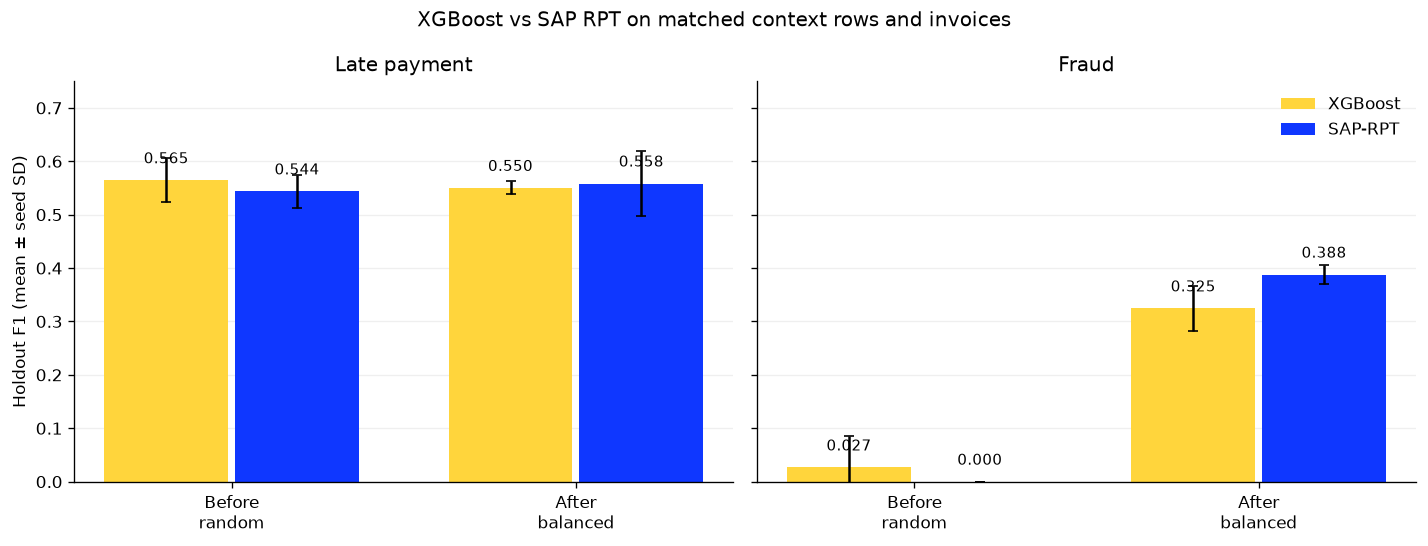

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
stage_labels = ['Before: random', 'After: balanced']
model_colors = {'XGBoost': '#FFD53C', 'SAP-RPT': '#0F37FF'}
for ax, (target, label) in zip(axes, targets.items()):
    subset = combined[combined.target == target]
    for model, offset in [('XGBoost', -0.19), ('SAP-RPT', 0.19)]:
        metric = (subset[subset.model == model].groupby('Stage').f1
                  .agg(['mean', 'std']).reindex(stage_labels))
        bars = ax.bar(np.arange(2) + offset, metric['mean'], width=0.36,
                      yerr=metric['std'], capsize=3, label=model,
                      color=model_colors[model])
        for bar, value in zip(bars, metric['mean']):
            ax.text(bar.get_x() + bar.get_width()/2, value + 0.025,
                    f'{value:.3f}', ha='center', va='bottom', fontsize=9)
    ax.set_xticks([0, 1], ['Before\nrandom', 'After\nbalanced'])
    ax.set_title(label)
    ax.set_ylim(0, 0.75)
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
axes[0].set_ylabel('Holdout F1 (mean ± seed SD)')
axes[1].legend(frameon=False, loc='upper right')
fig.suptitle('XGBoost vs SAP RPT on matched context rows and invoices')
fig.tight_layout()
plt.show()


### Fraud predictions: detections and false alarms
This table makes the positive-prediction tradeoff visible. There are eight actual fraud cases and 120 nonfraud cases in each holdout run.


In [ ]:
fraud_counts = (combined[combined.target == 'is_fraud']
                .groupby(['Stage', 'model'])[['true_positives', 'false_positives']]
                .agg(['mean', 'std']).round(2))
display(fraud_counts)

matched_sap_predictions = sap_predictions[sap_predictions.run_id.isin(sap.run_id)]
assert len(matched_sap_predictions) == len(sap) * len(query)
for result in sap.itertuples():
    predictions = matched_sap_predictions[matched_sap_predictions.run_id == result.run_id]
    checked = metric_row(predictions.actual.to_numpy(), predictions.predicted.to_numpy())
    assert np.isclose(checked['f1'], result.f1)
    assert checked['true_positives'] == result.true_positives
    assert checked['false_positives'] == result.false_positives


true_positives       false_positives      
                                  mean   std            mean   std
Stage           model                                             
After: balanced SAP-RPT            6.0  0.00            17.0  1.41
                XGBoost            5.8  0.45            22.2  3.11
Before: random  SAP-RPT            0.0  0.00             0.0  0.00
                XGBoost            0.2  0.45             3.8  2.86

## Takeaways

The table and chart above are the direct XGBoost versus SAP RPT comparison requested. Both stages use matched context rows and the same final invoices. Balanced context was selected using SAP RPT validation, so the XGBoost “after” result is an evaluation of that same intervention, not a separately tuned XGBoost strategy. Fraud has only eight holdout positives; inspect false alarms alongside F1 and recall. This synthetic experiment does not establish a general model ranking.
